# Linear Regression and Related Topics

## What linear regression is trying to do

## Why polynomial terms are still “linear regression”

## Underfitting  db

## Overfitting## Train/test evaluation and cross-validation

## Multicollinearity

## Variance Inflation Factor

## Interaction terms

## Practical modeling lessons

## In practice, linear regression is not just a line-fitting tool. It is a framework for building interpretable models using transformed features. Today’s goal is to understand how feature choices can make a model too simple, too flexible, unstable, or more realistic.

# Prerequisite insight: “Linear” means linear in the coefficients

## A model like
## $y = b_0 + b_1x + b_2x^2$
## is still a linear regression model because the unknown parameters $b_0, b_1, b_2$ enter linearly.
## The curve can bend, but the model is still fit using linear regression machinery.
## On the other hand, $y = \log(x + b_0)$ is nonlinear.

# Linear Regression and Polynomials
# Underfitting

## Why underfitting matters

## Underfitting happens when the model is too simple to capture the main structure in the data. In industry, this can lead to consistently wrong predictions, such as a pricing model that assumes demand changes linearly when the true relationship is curved.

## Question: if the true relationship is quadratic but we fit a straight line, then the residuals will be:

### a) Largest at the left and right ends, smallest in the middle.

### b) Largest at the left and right ends and in the middle.

### c) Largest in the middle.

### d) Smallest at the left and right ends and in the middle.

UNDERFITTING DEMO: linear fit to quadratic data

1. Generating 15 data points from a quadratic signal plus noise...
   x values: [-3.    -2.571 -2.143 -1.714 -1.286 -0.857 -0.429  0.     0.429  0.857
  1.286  1.714  2.143  2.571  3.   ]
   true equation: y = 2.0x^2 + (-0.5)x + 1.0
   noise mean/std: 0.016 / 1.491
   observed y: [21.245 15.303 12.227 10.019  4.598  2.547  3.95   2.151  0.449  2.855
  2.968  5.322  9.475 10.069 14.913]

2. Fitting a linear model with statsmodels.api as sm...
   statsmodels fit complete.
   fitted line: y = -0.9671x + 7.8727
   R-squared: 0.0938

   statsmodels summary:
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.094
Model:                            OLS   Adj. R-squared:                  0.024
Method:                 Least Squares   F-statistic:                     1.346
Date:                Sun, 06 Sep 2026   Prob (F-statistic):              0.2

/opt/homebrew/Caskroom/miniforge/base/envs/venv_mac_ML_keras/lib/python3.10/site-packages/scipy/stats/_axis_nan_policy.py:430: UserWarning: `kurtosistest` p-value may be inaccurate with fewer than 20 observations; only n=15 observations were given.
  return hypotest_fun_in(*args, **kwds)


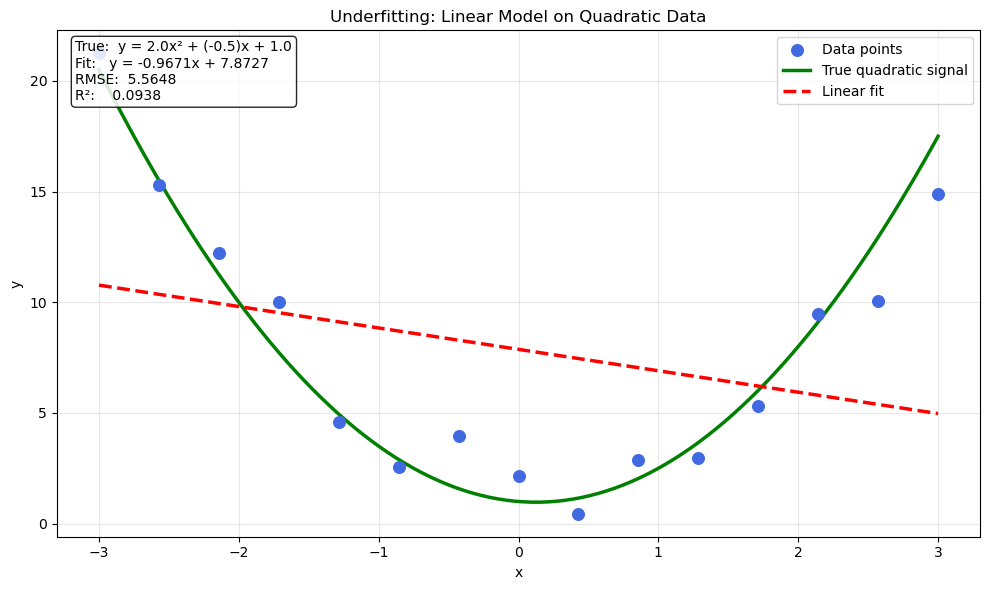


Done.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm

print("=" * 70)
print("UNDERFITTING DEMO: linear fit to quadratic data")
print("=" * 70)

# -----------------------------
# 1) Create quadratic data
# -----------------------------
print("\n1. Generating 15 data points from a quadratic signal plus noise...")

np.random.seed(42)
n = 15
x = np.linspace(-3, 3, n)

# True quadratic signal: y = ax^2 + bx + c
a_true = 2.0
b_true = -0.5
c_true = 1.0

y_true = a_true * x**2 + b_true * x + c_true
noise = np.random.normal(loc=0.0, scale=1.5, size=n)
y = y_true + noise

print(f"   x values: {np.round(x, 3)}")
print(f"   true equation: y = {a_true}x^2 + ({b_true})x + {c_true}")
print(f"   noise mean/std: {noise.mean():.3f} / {noise.std(ddof=1):.3f}")
print(f"   observed y: {np.round(y, 3)}")

# -----------------------------
# 2) Fit a linear model with statsmodels
# -----------------------------
print("\n2. Fitting a linear model with statsmodels.api as sm...")

X_sm = sm.add_constant(x)  # adds intercept term
ols_model = sm.OLS(y, X_sm)
ols_results = ols_model.fit()

intercept_sm, slope_sm = ols_results.params
print("   statsmodels fit complete.")
print(f"   fitted line: y = {slope_sm:.4f}x + {intercept_sm:.4f}")
print(f"   R-squared: {ols_results.rsquared:.4f}")

print("\n   statsmodels summary:")
print(ols_results.summary())

# -----------------------------
# 3) Fit a linear model with sklearn
# -----------------------------
print("\n3. Fitting a linear model with sklearn...")

X_sk = x.reshape(-1, 1)
lin_model = LinearRegression()
lin_model.fit(X_sk, y)

slope_sk = lin_model.coef_[0]
intercept_sk = lin_model.intercept_

print(f"   sklearn fitted line: y = {slope_sk:.4f}x + {intercept_sk:.4f}")
print(f"   coefficients match statsmodels: {np.allclose([intercept_sm, slope_sm], [intercept_sk, slope_sk])}")

# -----------------------------
# 4) Evaluate fit
# -----------------------------
print("\n4. Evaluating fit quality...")

y_pred = ols_results.predict(X_sm)
residuals = y - y_pred

mse = np.mean((y - y_pred) ** 2)
rmse = np.sqrt(mse)

print(f"   MSE:  {mse:.4f}")
print(f"   RMSE: {rmse:.4f}")
print(f"   residuals: {np.round(residuals, 3)}")
print("\n   equation arrived at by linear fit:")
print(f"   y = {slope_sm:.4f}x + {intercept_sm:.4f}")

# -----------------------------
# 5) Plot true signal, data, and linear fit
# -----------------------------
print("\n5. Plotting the quadratic signal, noisy points, and linear fit...")

x_plot = np.linspace(x.min(), x.max(), 300)
y_true_plot = a_true * x_plot**2 + b_true * x_plot + c_true
y_fit_plot = slope_sm * x_plot + intercept_sm

plt.figure(figsize=(10, 6))
plt.scatter(x, y, color="royalblue", s=70, label="Data points", zorder=3)
plt.plot(x_plot, y_true_plot, color="green", linewidth=2.5, label="True quadratic signal")
plt.plot(x_plot, y_fit_plot, color="red", linestyle="--", linewidth=2.5, label="Linear fit")

plt.title("Underfitting: Linear Model on Quadratic Data")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, alpha=0.3)
plt.legend()

equation_text = (
    f"True:  y = {a_true}x² + ({b_true})x + {c_true}\n"
    f"Fit:   y = {slope_sm:.4f}x + {intercept_sm:.4f}\n"
    f"RMSE:  {rmse:.4f}\n"
    f"R²:    {ols_results.rsquared:.4f}"
)
plt.gca().text(
    0.02, 0.98, equation_text,
    transform=plt.gca().transAxes,
    va="top", ha="left",
    fontsize=10,
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.85)
)

plt.tight_layout()
plt.show()

print("\nDone.")

#print(1 - ((y - y_pred)**2).mean() / ((y - y.mean())**2).mean())

## Misconception 1: “Linear regression means a straight-line relationship”

QUADRATIC FIT DEMO: linear regression with a quadratic term

1. Generating the same 15 data points from a quadratic signal plus noise...
   x values: [-3.    -2.571 -2.143 -1.714 -1.286 -0.857 -0.429  0.     0.429  0.857
  1.286  1.714  2.143  2.571  3.   ]
   true equation: y = 2.0x^2 + (-0.5)x + 1.0
   observed y: [21.245 15.303 12.227 10.019  4.598  2.547  3.95   2.151  0.449  2.855
  2.968  5.322  9.475 10.069 14.913]

2. Creating quadratic features: [1, x, x^2]...
   feature matrix created with columns:
   - constant term
   - x
   - x^2

3. Fitting quadratic regression with statsmodels.api as sm...
   statsmodels fit complete.
   fitted equation: y = 1.7986x^2 + (-0.9671)x + 1.7059
   R-squared: 0.9722

   statsmodels summary:
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.972
Model:                            OLS   Adj. R-squared:                  0.968
Method:             

/opt/homebrew/Caskroom/miniforge/base/envs/venv_mac_ML_keras/lib/python3.10/site-packages/scipy/stats/_axis_nan_policy.py:430: UserWarning: `kurtosistest` p-value may be inaccurate with fewer than 20 observations; only n=15 observations were given.
  return hypotest_fun_in(*args, **kwds)


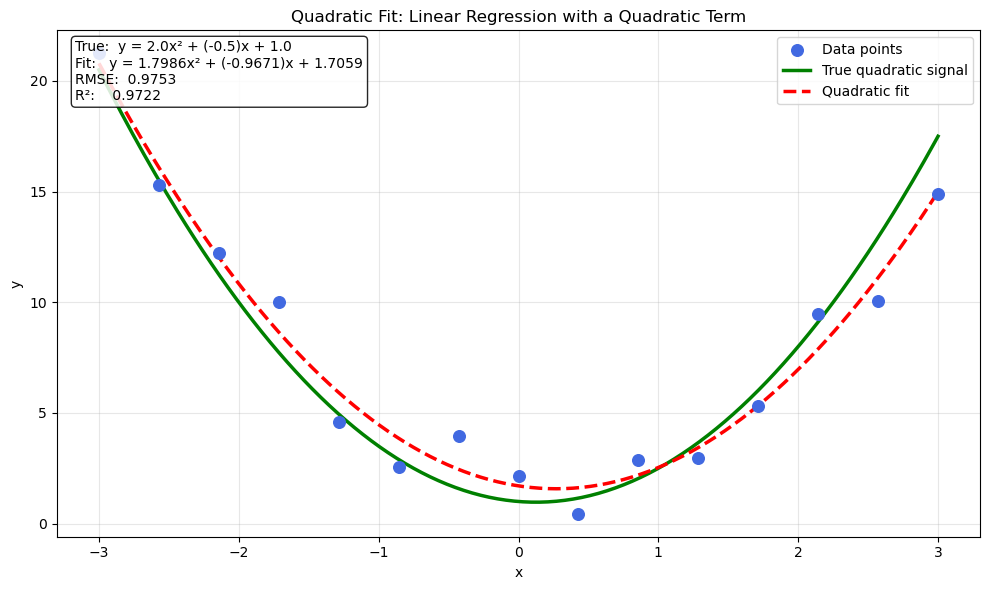


Done.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm

print("=" * 70)
print("QUADRATIC FIT DEMO: linear regression with a quadratic term")
print("=" * 70)

# -----------------------------
# 1) Create the same quadratic data
# -----------------------------
print("\n1. Generating the same 15 data points from a quadratic signal plus noise...")

np.random.seed(42)
n = 15
x = np.linspace(-3, 3, n)

# True quadratic signal: y = ax^2 + bx + c
a_true = 2.0
b_true = -0.5
c_true = 1.0

y_true = a_true * x**2 + b_true * x + c_true
noise = np.random.normal(loc=0.0, scale=1.5, size=n)
y = y_true + noise

print(f"   x values: {np.round(x, 3)}")
print(f"   true equation: y = {a_true}x^2 + ({b_true})x + {c_true}")
print(f"   observed y: {np.round(y, 3)}")

# -----------------------------
# 2) Build quadratic features
# -----------------------------
print("\n2. Creating quadratic features: [1, x, x^2]...")

X_quad = np.column_stack([x, x**2])
X_quad_sm = sm.add_constant(X_quad)

print("   feature matrix created with columns:")
print("   - constant term")
print("   - x")
print("   - x^2")

# -----------------------------
# 3) Fit quadratic model with statsmodels
# -----------------------------
print("\n3. Fitting quadratic regression with statsmodels.api as sm...")

quad_model = sm.OLS(y, X_quad_sm)
quad_results = quad_model.fit()

c_sm, b_sm, a_sm = quad_results.params
print("   statsmodels fit complete.")
print(f"   fitted equation: y = {a_sm:.4f}x^2 + ({b_sm:.4f})x + {c_sm:.4f}")
print(f"   R-squared: {quad_results.rsquared:.4f}")

print("\n   statsmodels summary:")
print(quad_results.summary())

# -----------------------------
# 4) Fit quadratic model with sklearn
# -----------------------------
print("\n4. Fitting quadratic regression with sklearn...")

lin_model = LinearRegression()
lin_model.fit(X_quad, y)

b_sk = lin_model.coef_[0]
a_sk = lin_model.coef_[1]
c_sk = lin_model.intercept_

print(f"   sklearn fitted equation: y = {a_sk:.4f}x^2 + ({b_sk:.4f})x + {c_sk:.4f}")
print(f"   coefficients match statsmodels: {np.allclose([c_sm, b_sm, a_sm], [c_sk, b_sk, a_sk])}")

# -----------------------------
# 5) Evaluate fit
# -----------------------------
print("\n5. Evaluating fit quality...")

y_pred = quad_results.predict(X_quad_sm)
residuals = y - y_pred

mse = np.mean((y - y_pred) ** 2)
rmse = np.sqrt(mse)

print(f"   MSE:  {mse:.4f}")
print(f"   RMSE: {rmse:.4f}")
print(f"   residuals: {np.round(residuals, 3)}")
print("\n   equation arrived at by quadratic fit:")
print(f"   y = {a_sm:.4f}x^2 + ({b_sm:.4f})x + {c_sm:.4f}")

# -----------------------------
# 6) Plot true signal, data, and quadratic fit
# -----------------------------
print("\n6. Plotting the quadratic signal, noisy points, and quadratic fit...")

x_plot = np.linspace(x.min(), x.max(), 300)
y_true_plot = a_true * x_plot**2 + b_true * x_plot + c_true
y_fit_plot = a_sm * x_plot**2 + b_sm * x_plot + c_sm

plt.figure(figsize=(10, 6))
plt.scatter(x, y, color="royalblue", s=70, label="Data points", zorder=3)
plt.plot(x_plot, y_true_plot, color="green", linewidth=2.5, label="True quadratic signal")
plt.plot(x_plot, y_fit_plot, color="red", linestyle="--", linewidth=2.5, label="Quadratic fit")

plt.title("Quadratic Fit: Linear Regression with a Quadratic Term")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, alpha=0.3)
plt.legend()

equation_text = (
    f"True:  y = {a_true}x² + ({b_true})x + {c_true}\n"
    f"Fit:   y = {a_sm:.4f}x² + ({b_sm:.4f})x + {c_sm:.4f}\n"
    f"RMSE:  {rmse:.4f}\n"
    f"R²:    {quad_results.rsquared:.4f}"
)
plt.gca().text(
    0.02, 0.98, equation_text,
    transform=plt.gca().transAxes,
    va="top", ha="left",
    fontsize=10,
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.85)
)

plt.tight_layout()
plt.show()

print("\nDone.")

## Question: If a model has training RMSE = 0, does that guarantee it is a good model?  Why or why not?

# Overfitting

## Why overfitting matters

## Overfitting happens when a model learns accidental noise in the training data. It may look excellent on past data but fail on future customers, future sales, future patients, or future transactions.

In [3]:
# Put this cell in place of the current "Overfitting" polynomial degree-N demo.
# Best location: immediately after the "Quadratic Fit Demo" section and before
# the "Validation of polynomial linear regression" / "Cross-Validation" sections.
#
# This version keeps the controls directly above the graph and moves the longer
# explanation below the graph so students can see the sliders and visual result
# on the same screen.

import numpy as np
import matplotlib.pyplot as plt

import ipywidgets as widgets
from IPython.display import display, Markdown
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score


degree_slider = widgets.IntSlider(
    value=2,
    min=1,
    max=14,
    step=1,
    description="Degree",
    continuous_update=False,
)

noise_slider = widgets.FloatSlider(
    value=1.5,
    min=0.0,
    max=5.0,
    step=0.25,
    description="Noise",
    continuous_update=False,
)

n_train_slider = widgets.IntSlider(
    value=15,
    min=8,
    max=80,
    step=1,
    description="Train n",
    continuous_update=False,
)

seed_slider = widgets.IntSlider(
    value=42,
    min=0,
    max=100,
    step=1,
    description="Seed",
    continuous_update=False,
)

show_true_checkbox = widgets.Checkbox(
    value=True,
    description="True signal",
)

show_test_checkbox = widgets.Checkbox(
    value=True,
    description="Test data",
)

show_extrapolation_checkbox = widgets.Checkbox(
    value=False,
    description="Extrapolation",
)

controls = widgets.VBox(
    [
        widgets.HTML(
            value="""
            <h2 style="margin-bottom: 0px;">Interactive Polynomial Regression Demo</h2>
            <p style="margin-top: 4px; margin-bottom: 8px;">
            Change the polynomial degree, noise level, or training sample size.
            Watch how the fitted curve and train/test performance change.
            </p>
            """
        ),
        widgets.HBox([degree_slider, noise_slider, n_train_slider, seed_slider]),
        widgets.HBox([show_true_checkbox, show_test_checkbox, show_extrapolation_checkbox]),
    ]
)

output = widgets.Output()


def polynomial_interactive_demo(change=None):
    degree = degree_slider.value
    noise_sd = noise_slider.value
    n_train = n_train_slider.value
    seed = seed_slider.value
    show_true_signal = show_true_checkbox.value
    show_test_data = show_test_checkbox.value
    show_extrapolation = show_extrapolation_checkbox.value

    n_test = 200

    with output:
        output.clear_output(wait=True)

        rng = np.random.default_rng(seed)

        a_true = 2.0
        b_true = -0.5
        c_true = 1.0

        x_train = np.linspace(-3, 3, n_train)
        y_true_train = a_true * x_train**2 + b_true * x_train + c_true
        y_train = y_true_train + rng.normal(0.0, noise_sd, size=n_train)

        x_test = rng.uniform(-3, 3, n_test)
        x_test = np.sort(x_test)
        y_true_test = a_true * x_test**2 + b_true * x_test + c_true
        y_test = y_true_test + rng.normal(0.0, noise_sd, size=n_test)

        model = Pipeline(
            [
                ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
                ("lr", LinearRegression()),
            ]
        )

        model.fit(x_train.reshape(-1, 1), y_train)

        y_train_pred = model.predict(x_train.reshape(-1, 1))
        y_test_pred = model.predict(x_test.reshape(-1, 1))

        train_rmse = mean_squared_error(y_train, y_train_pred) ** 0.5
        test_rmse = mean_squared_error(y_test, y_test_pred) ** 0.5

        train_r2 = r2_score(y_train, y_train_pred)
        test_r2 = r2_score(y_test, y_test_pred)

        if show_extrapolation:
            x_min_plot = -4.5
            x_max_plot = 4.5
        else:
            x_min_plot = -3.0
            x_max_plot = 3.0

        x_plot = np.linspace(x_min_plot, x_max_plot, 800)
        y_true_plot = a_true * x_plot**2 + b_true * x_plot + c_true
        y_fit_plot = model.predict(x_plot.reshape(-1, 1))

        fig, ax = plt.subplots(figsize=(10.5, 5.8))

        if show_true_signal:
            ax.plot(
                x_plot,
                y_true_plot,
                color="green",
                linewidth=2.5,
                label="True quadratic signal",
                zorder=1,
            )

        ax.plot(
            x_plot,
            y_fit_plot,
            color="red",
            linestyle="--",
            linewidth=2.5,
            label=f"Fitted polynomial degree {degree}",
            zorder=2,
        )

        ax.scatter(
            x_train,
            y_train,
            color="royalblue",
            s=75,
            edgecolor="black",
            linewidth=0.8,
            label="Training data",
            zorder=4,
        )

        if show_test_data:
            ax.scatter(
                x_test,
                y_test,
                color="orange",
                s=22,
                alpha=0.42,
                label="Test data",
                zorder=3,
            )

        if show_extrapolation:
            ax.axvspan(-4.5, -3.0, color="gray", alpha=0.12, label="Extrapolation region")
            ax.axvspan(3.0, 4.5, color="gray", alpha=0.12)

        ax.set_title("Polynomial Regression: Underfitting, Good Fit, and Overfitting")
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.grid(True, alpha=0.3)

        metrics_text = (
            f"Degree = {degree}\n"
            f"Train RMSE = {train_rmse:.3f}\n"
            f"Test RMSE = {test_rmse:.3f}\n"
            f"Train R² = {train_r2:.3f}\n"
            f"Test R² = {test_r2:.3f}"
        )

        ax.text(
            0.02,
            0.98,
            metrics_text,
            transform=ax.transAxes,
            va="top",
            ha="left",
            fontsize=10.5,
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.9),
        )

        ax.legend(loc="best")
        plt.tight_layout()
        plt.show()

        if degree == 1:
            interpretation = "Degree 1 is a straight-line model. It usually underfits this curved signal."
        elif degree == 2:
            interpretation = "Degree 2 matches the true data-generating structure in this example."
        elif degree >= n_train - 1:
            interpretation = "This degree is high enough to nearly memorize the training data. Be suspicious of excellent training performance."
        elif degree >= 6:
            interpretation = "This degree is quite flexible. Watch for unnecessary wiggles and poorer test performance."
        else:
            interpretation = "This degree adds flexibility. Compare training error and test error carefully."

        display(
            Markdown(
                f"""
### Interpretation

**Polynomial regression is still linear regression** because the model is linear in the fitted coefficients, even when the curve bends as a function of `x`.

Current setting:

- Polynomial degree: **{degree}**
- Training points: **{n_train}**
- Noise standard deviation: **{noise_sd}**
- Training RMSE: **{train_rmse:.3f}**
- Test RMSE: **{test_rmse:.3f}**
- Training R²: **{train_r2:.3f}**
- Test R²: **{test_r2:.3f}**

**Teaching note:** {interpretation}

A perfect or near-perfect training fit is not enough. In modeling practice, we care about whether the model generalizes to new data.
"""
            )
        )


for widget in [
    degree_slider,
    noise_slider,
    n_train_slider,
    seed_slider,
    show_true_checkbox,
    show_test_checkbox,
    show_extrapolation_checkbox,
]:
    widget.observe(polynomial_interactive_demo, names="value")


display(controls, output)
polynomial_interactive_demo()

Output()

In [4]:
R squared = 1 - SSE(our model) / SSE(mean model)

SyntaxError: invalid syntax (2083114108.py, line 1)

## Misconception 2: “High R² means the model is good”

# Validation of polynomial linear regression (via graph)

POLYNOMIAL FIT DEMO: degree-N polynomial regression

Using polynomial degree N = 14

1. Generating 15 training data points from a quadratic signal plus noise...
   x_train values: [-3.    -2.571 -2.143 -1.714 -1.286 -0.857 -0.429  0.     0.429  0.857
  1.286  1.714  2.143  2.571  3.   ]
   observed y_train: [21.245 15.303 12.227 10.019  4.598  2.547  3.95   2.151  0.449  2.855
  2.968  5.322  9.475 10.069 14.913]

2. Creating polynomial features up to degree 14...
   feature columns:
   - x
   - x^2
   - x^3
   - x^4
   - x^5
   - x^6
   - x^7
   - x^8
   - x^9
   - x^10
   - x^11
   - x^12
   - x^13
   - x^14

3. Fitting polynomial regression with statsmodels.api as sm...
   statsmodels fit complete.
   training R-squared: 1.0000

4. Fitting polynomial regression with sklearn...
   sklearn fit complete.
   coefficients match statsmodels: True

5. Evaluating training fit quality...
   training MSE:  0.0000
   training RMSE: 0.0000
   training R-squared: 1.0000

6. Generating NEW data h

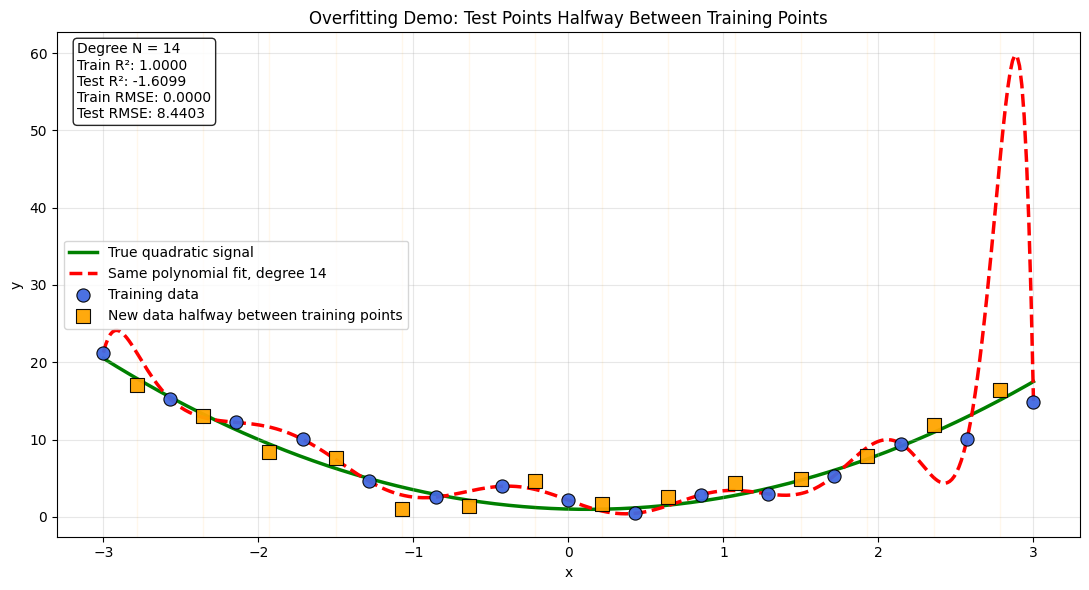

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm

print("=" * 70)
print("POLYNOMIAL FIT DEMO: degree-N polynomial regression")
print("=" * 70)

# -----------------------------
# User-adjustable polynomial degree
# -----------------------------
N = 14   # change this to any nonnegative integer degree
print(f"\nUsing polynomial degree N = {N}")

# -----------------------------
# 1) Create the training data
# -----------------------------
print("\n1. Generating 15 training data points from a quadratic signal plus noise...")

np.random.seed(42)
n_train = 15
x_train = np.linspace(-3, 3, n_train)

# True quadratic signal
a_true = 2.0
b_true = -0.5
c_true = 1.0

y_true_train = a_true * x_train**2 + b_true * x_train + c_true
noise_train = np.random.normal(loc=0.0, scale=1.5, size=n_train)
y_train = y_true_train + noise_train

print(f"   x_train values: {np.round(x_train, 3)}")
print(f"   observed y_train: {np.round(y_train, 3)}")

# -----------------------------
# 2) Create polynomial features
# -----------------------------
print(f"\n2. Creating polynomial features up to degree {N}...")

poly = PolynomialFeatures(degree=N, include_bias=False)
X_train_poly = poly.fit_transform(x_train.reshape(-1, 1))

feature_names = poly.get_feature_names_out(["x"])
print("   feature columns:")
for name in feature_names:
    print(f"   - {name}")

# Add intercept for statsmodels
X_train_poly_sm = sm.add_constant(X_train_poly, has_constant="add")

# -----------------------------
# 3) Fit polynomial regression with statsmodels
# -----------------------------
print("\n3. Fitting polynomial regression with statsmodels.api as sm...")

poly_model = sm.OLS(y_train, X_train_poly_sm)
poly_results = poly_model.fit()

params = poly_results.params
intercept_sm = params[0]
coefs_sm = params[1:]

print("   statsmodels fit complete.")
print(f"   training R-squared: {poly_results.rsquared:.4f}")

# -----------------------------
# 4) Fit polynomial regression with sklearn
# -----------------------------
print("\n4. Fitting polynomial regression with sklearn...")

sk_model = LinearRegression()
sk_model.fit(X_train_poly, y_train)

intercept_sk = sk_model.intercept_
coefs_sk = sk_model.coef_

print("   sklearn fit complete.")
print(
    f"   coefficients match statsmodels: "
    f"{np.allclose(np.r_[intercept_sm, coefs_sm], np.r_[intercept_sk, coefs_sk])}"
)

# -----------------------------
# 5) Evaluate fit on training data
# -----------------------------
print("\n5. Evaluating training fit quality...")

y_train_pred = poly_results.predict(X_train_poly_sm)
train_mse = np.mean((y_train - y_train_pred) ** 2)
train_rmse = np.sqrt(train_mse)

ss_res_train = np.sum((y_train - y_train_pred) ** 2)
ss_tot_train = np.sum((y_train - np.mean(y_train)) ** 2)
r2_train = 1 - ss_res_train / ss_tot_train

print(f"   training MSE:  {train_mse:.4f}")
print(f"   training RMSE: {train_rmse:.4f}")
print(f"   training R-squared: {r2_train:.4f}")

# -----------------------------
# 6) Generate NEW data with a NEW random seed
#    Test points are halfway between training points
# -----------------------------
print("\n6. Generating NEW data halfway between training points...")

np.random.seed(40)

spacing = x_train[1] - x_train[0]
x_test = x_train[:-1] + spacing / 2
n_test = len(x_test)

y_true_test = a_true * x_test**2 + b_true * x_test + c_true
noise_test = np.random.normal(loc=0.0, scale=1.5, size=n_test)
y_test = y_true_test + noise_test

print(f"   x_test values: {np.round(x_test, 3)}")
print(f"   observed y_test: {np.round(y_test, 3)}")

# Use the SAME fitted model on the new data
X_test_poly = poly.transform(x_test.reshape(-1, 1))
X_test_poly_sm = sm.add_constant(X_test_poly, has_constant="add")

y_test_pred = poly_results.predict(X_test_poly_sm)

test_mse = np.mean((y_test - y_test_pred) ** 2)
test_rmse = np.sqrt(test_mse)

ss_res_test = np.sum((y_test - y_test_pred) ** 2)
ss_tot_test = np.sum((y_test - np.mean(y_test)) ** 2)
r2_test = 1 - ss_res_test / ss_tot_test

print(f"\n   new-data MSE:  {test_mse:.4f}")
print(f"   new-data RMSE: {test_rmse:.4f}")
print(f"   new-data R-squared: {r2_test:.4f}")

# -----------------------------
# 7) Plot training data, new data, true signal, and same fitted line
# -----------------------------
print("\n7. Plotting the original fit over both datasets...")

x_plot = np.linspace(-3, 3, 400)
y_true_plot = a_true * x_plot**2 + b_true * x_plot + c_true

X_plot_poly = poly.transform(x_plot.reshape(-1, 1))
X_plot_poly_sm = sm.add_constant(X_plot_poly, has_constant="add")
y_fit_plot = poly_results.predict(X_plot_poly_sm)

plt.figure(figsize=(11, 6))

# true signal first
plt.plot(
    x_plot,
    y_true_plot,
    color="green",
    linewidth=2.5,
    label="True quadratic signal",
    zorder=1
)

# fitted polynomial
plt.plot(
    x_plot,
    y_fit_plot,
    color="red",
    linestyle="--",
    linewidth=2.5,
    label=f"Same polynomial fit, degree {N}",
    zorder=2
)

# training data
plt.scatter(
    x_train,
    y_train,
    color="royalblue",
    s=90,
    edgecolor="black",
    linewidth=0.8,
    alpha=0.95,
    label="Training data",
    zorder=4
)

# new midpoint data
plt.scatter(
    x_test,
    y_test,
    color="orange",
    s=90,
    marker="s",
    edgecolor="black",
    linewidth=0.8,
    alpha=0.95,
    label="New data halfway between training points",
    zorder=3
)

# Optional: draw faint vertical lines to make midpoint placement obvious
for x in x_test:
    plt.axvline(x=x, color="orange", alpha=0.08, linewidth=1)

plt.title("Overfitting Demo: Test Points Halfway Between Training Points")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, alpha=0.3)
plt.legend()

equation_text = (
    f"Degree N = {N}\n"
    f"Train R²: {r2_train:.4f}\n"
    f"Test R²: {r2_test:.4f}\n"
    f"Train RMSE: {train_rmse:.4f}\n"
    f"Test RMSE: {test_rmse:.4f}"
)

plt.gca().text(
    0.02,
    0.98,
    equation_text,
    transform=plt.gca().transAxes,
    va="top",
    ha="left",
    fontsize=10,
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.85)
)

plt.tight_layout()
plt.show()

## Question: Why should we not choose polynomial degree using training error?

# Cross-Validation

## Why cross-validation matters

## You will use cross-validation in your projects in order to avoid overfitting.  Cross-validation avoids overfitting by separating training data from testing data.  It is more reliable than a train-test split because many different splits are used, just in case one split behaves in an unusual way.

## Prerequisite refresher: what cross-validation is doing

## We do not choose a model by asking how well it memorizes the training data. We choose a model by estimating how well it predicts data it did not train on.

## Misconception 3: “Training error is enough to choose a model”

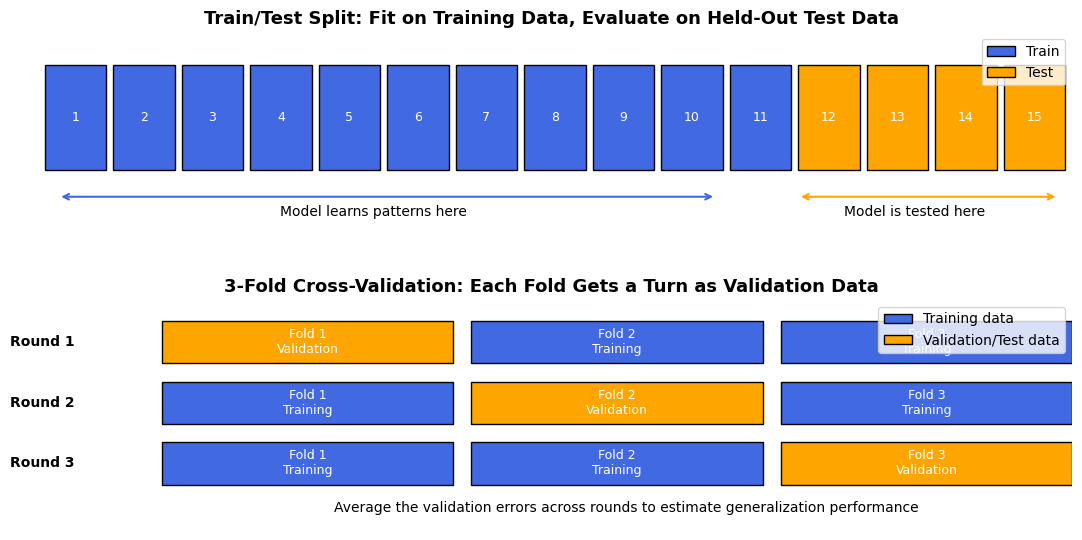

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

fig, axes = plt.subplots(2, 1, figsize=(11, 5.5))

# -----------------------------
# Diagram 1: Simple train/test split
# -----------------------------
ax = axes[0]
ax.set_title("Train/Test Split: Fit on Training Data, Evaluate on Held-Out Test Data", fontsize=13, weight="bold")

n_blocks = 15
test_blocks = {11, 12, 13, 14}

for i in range(n_blocks):
    color = "royalblue" if i not in test_blocks else "orange"
    label = "Train" if i == 0 else ("Test" if i == 11 else None)

    ax.add_patch(
        Rectangle(
            (i, 0),
            0.9,
            0.8,
            facecolor=color,
            edgecolor="black",
            linewidth=1.0,
            label=label,
        )
    )
    ax.text(i + 0.45, 0.4, str(i + 1), ha="center", va="center", color="white", fontsize=9)

ax.text(4.8, -0.35, "Model learns patterns here", ha="center", fontsize=10)
ax.text(12.7, -0.35, "Model is tested here", ha="center", fontsize=10)

ax.annotate(
    "",
    xy=(9.8, -0.2),
    xytext=(0.2, -0.2),
    arrowprops=dict(arrowstyle="<->", linewidth=1.5, color="royalblue"),
)

ax.annotate(
    "",
    xy=(14.8, -0.2),
    xytext=(11.0, -0.2),
    arrowprops=dict(arrowstyle="<->", linewidth=1.5, color="orange"),
)

ax.set_xlim(-0.2, n_blocks)
ax.set_ylim(-0.7, 1.05)
ax.axis("off")
ax.legend(loc="upper right")


# -----------------------------
# Diagram 2: 3-fold cross-validation
# -----------------------------
ax = axes[1]
ax.set_title("3-Fold Cross-Validation: Each Fold Gets a Turn as Validation Data", fontsize=13, weight="bold")

folds = [
    {"name": "Round 1", "val": 0},
    {"name": "Round 2", "val": 1},
    {"name": "Round 3", "val": 2},
]

fold_labels = ["Fold 1", "Fold 2", "Fold 3"]
fold_width = 4
gap = 0.25

for row, fold_info in enumerate(folds):
    y = 2 - row

    ax.text(-1.2, y + 0.35, fold_info["name"], ha="right", va="center", fontsize=10, weight="bold")

    for fold_idx in range(3):
        x0 = fold_idx * (fold_width + gap)
        is_validation = fold_idx == fold_info["val"]
        color = "orange" if is_validation else "royalblue"
        label = "Validation" if is_validation else "Training"

        ax.add_patch(
            Rectangle(
                (x0, y),
                fold_width,
                0.7,
                facecolor=color,
                edgecolor="black",
                linewidth=1.0,
            )
        )

        ax.text(
            x0 + fold_width / 2,
            y + 0.35,
            f"{fold_labels[fold_idx]}\n{label}",
            ha="center",
            va="center",
            color="white",
            fontsize=9,
        )

ax.text(
    1.5 * (fold_width + gap),
    -0.45,
    "Average the validation errors across rounds to estimate generalization performance",
    ha="center",
    fontsize=10,
)

ax.set_xlim(-1.8, 3 * (fold_width + gap) - gap)
ax.set_ylim(-0.75, 3.05)
ax.axis("off")

legend_handles = [
    Rectangle((0, 0), 1, 1, facecolor="royalblue", edgecolor="black", label="Training data"),
    Rectangle((0, 0), 1, 1, facecolor="orange", edgecolor="black", label="Validation/Test data"),
]
ax.legend(handles=legend_handles, loc="upper right")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.metrics import mean_squared_error

print("=" * 70)
print("CROSS-VALIDATION COMPARISON: polynomial degrees 1, 2, and 3, 6, and 9")
print("=" * 70)

# -----------------------------
# 1) Same data as before
# -----------------------------
print("\n1. Generating the same 15 data points from a quadratic signal plus noise...")

np.random.seed(42)
n = 15
x = np.linspace(-3, 3, n).reshape(-1, 1)

a_true = 2.0
b_true = -0.5
c_true = 1.0

y_true = a_true * x.ravel()**2 + b_true * x.ravel() + c_true
noise = np.random.normal(loc=0.0, scale=1.5, size=n)
y = y_true + noise

print(f"   true equation: y = {a_true}x^2 + ({b_true})x + {c_true}")
print(f"   observed y: {np.round(y, 3)}")

# -----------------------------
# 2) Define models
# -----------------------------
degrees = [1, 2, 3, 4, 9]
models = {}

for d in degrees:
    models[d] = Pipeline([
        ("poly", PolynomialFeatures(degree=d, include_bias=False)),
        ("lr", LinearRegression())
    ])

# -----------------------------
# 3) Cross-validation
# -----------------------------
folds = 3
print(f"\n2. Running {folds}-fold cross-validation (scoring = negative MSE)...")
kf = KFold(n_splits=folds, shuffle=True, random_state=42)

cv_results = {}

for d in degrees:
    scores = cross_val_score(models[d], x, y, cv=kf, scoring="neg_mean_squared_error")
    mse_scores = -scores
    cv_results[d] = {
        "mean_mse": mse_scores.mean(),
        "std_mse": mse_scores.std(ddof=1),
        "fold_mse": mse_scores
    }
    print(f"   degree {d}: fold MSEs = {np.round(mse_scores, 4)}")
    print(f"              mean MSE = {mse_scores.mean():.4f} +/- {mse_scores.std(ddof=1):.4f}")

best_degree_cv = min(cv_results, key=lambda d: cv_results[d]["mean_mse"])

print("\n3. Best model by cross-validation:")
print(f"   degree {best_degree_cv} has the smallest mean validation MSE")

# -----------------------------
# 4) Optional hold-out test split
# -----------------------------
print("\n4. Running a train/test split for a simple test-data comparison...")

X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.33, random_state=42
)

test_results = {}

for d in degrees:
    model = models[d]
    model.fit(X_train, y_train)
    y_pred_test = model.predict(X_test)
    test_mse = mean_squared_error(y_test, y_pred_test)
    test_results[d] = test_mse
    print(f"   degree {d}: test MSE = {test_mse:.4f}")

best_degree_test = min(test_results, key=test_results.get)

print("\n5. Best model by test data:")
print(f"   degree {best_degree_test} has the smallest test MSE")

# -----------------------------
# 5) Summary
# -----------------------------
print("\n" + "=" * 70)
print("SUMMARY")
print("=" * 70)

for d in degrees:
    print(
        f"degree {d}: "
        f"CV mean MSE = {cv_results[d]['mean_mse']:.4f}, "
        f"Test MSE = {test_results[d]:.4f}"
    )

print("\nConclusion:")
print(f"   Cross-validation prefers degree {best_degree_cv}.")
print(f"   Test split prefers degree {best_degree_test}.")
print("   In this data, degree 2 is usually the best choice because the true signal is quadratic.")

CROSS-VALIDATION COMPARISON: polynomial degrees 1, 2, and 3, 6, and 9

1. Generating the same 15 data points from a quadratic signal plus noise...
   true equation: y = 2.0x^2 + (-0.5)x + 1.0
   observed y: [21.245 15.303 12.227 10.019  4.598  2.547  3.95   2.151  0.449  2.855
  2.968  5.322  9.475 10.069 14.913]

2. Running 3-fold cross-validation (scoring = negative MSE)...
   degree 1: fold MSEs = [44.0964 44.408  20.3449]
              mean MSE = 36.2831 +/- 13.8038
   degree 2: fold MSEs = [0.8999 1.5752 2.8232]
              mean MSE = 1.7661 +/- 0.9758
   degree 3: fold MSEs = [1.1482 1.5416 3.1359]
              mean MSE = 1.9419 +/- 1.0526
   degree 4: fold MSEs = [3.4142 2.7726 3.1367]
              mean MSE = 3.1078 +/- 0.3217
   degree 9: fold MSEs = [4.97146380e+03 1.50972023e+04 8.83490000e+00]
              mean MSE = 6692.5003 +/- 7690.0054

3. Best model by cross-validation:
   degree 2 has the smallest mean validation MSE

4. Running a train/test split for a simple te

## Question: If two predictors (features) are almost identical, can the model still predict well? Can it reliably estimate each variable’s separate effect?  Why or why not?

# Multicollinearity

## Why Multicollinearity matters

## Multicollinearity occurs in real data sets when one column is a linear combination of two or more other columns.  It's important to be able to deal with that when it happens.

Multicollinearity demo with target correlation rho = 0.0
Generating n = 200 observations
Model: Y = 2.0*X1 + 3.0*X2 + noise, noise_sd = 1.0

Sample correlation corr(X1, X2) = -0.0282
Plotting X1 vs X2...


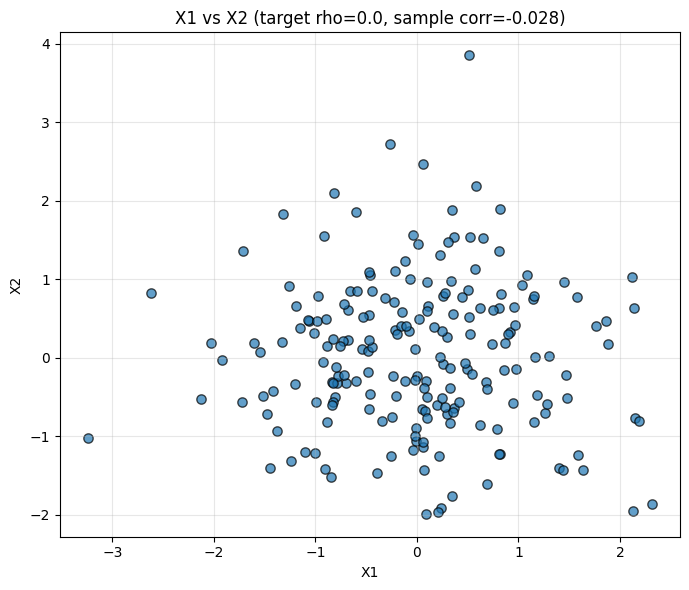


Head of the X1, X2, Y table:
       X1        X2         Y
 0.496714 -0.138264 -1.015792
 0.647689  1.523030  5.265092
-0.234153 -0.234137 -1.165474
 1.579213  0.767435  5.507710
-0.469474  0.542560  0.238666

Fitting OLS regression with statsmodels...

Statsmodels coefficients and standard errors:
           coef      bses
const -0.087890  0.070493
X1     2.066145  0.073751
X2     3.046836  0.073206

Regression summary:
                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.926
Model:                            OLS   Adj. R-squared:                  0.925
Method:                 Least Squares   F-statistic:                     1227.
Date:                Thu, 14 May 2026   Prob (F-statistic):          6.49e-112
Time:                        09:44:30   Log-Likelihood:                -281.49
No. Observations:                 200   AIC:                             569.0
Df Residuals:        

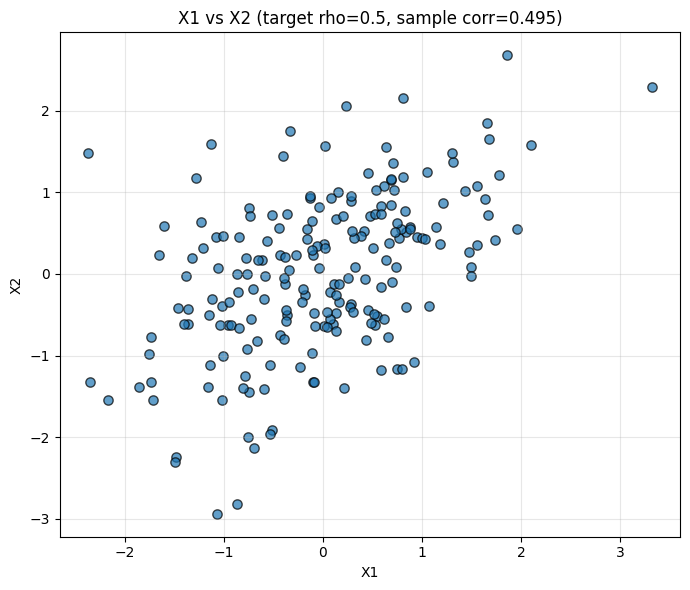


Head of the X1, X2, Y table:
       X1        X2         Y
-0.361035 -0.499299 -3.814395
-1.322430  0.200600 -2.642434
 0.319851  0.085714  0.902089
-1.751356 -0.983921 -6.407494
 0.135297  0.677857  1.854098

Fitting OLS regression with statsmodels...

Statsmodels coefficients and standard errors:
           coef      bses
const -0.087890  0.070493
X1     1.914975  0.085722
X2     3.008647  0.083644

Regression summary:
                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.946
Model:                            OLS   Adj. R-squared:                  0.945
Method:                 Least Squares   F-statistic:                     1713.
Date:                Thu, 14 May 2026   Prob (F-statistic):          2.77e-125
Time:                        09:44:30   Log-Likelihood:                -281.49
No. Observations:                 200   AIC:                             569.0
Df Residuals:        

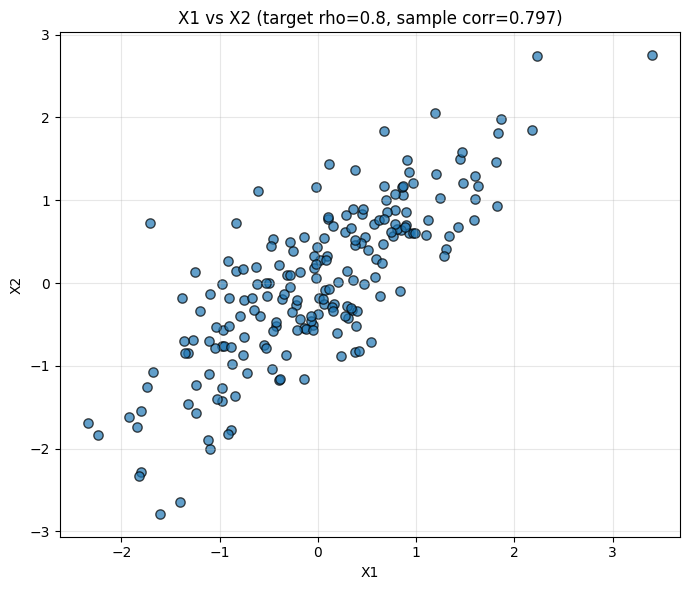


Head of the X1, X2, Y table:
       X1        X2         Y
-0.427501 -0.514947 -3.994273
-1.096076 -0.132827 -3.190007
 0.296178  0.148097  1.041890
-1.740857 -1.255489 -7.201199
 0.273810  0.616955  1.948420

Fitting OLS regression with statsmodels...

Statsmodels coefficients and standard errors:
           coef      bses
const -0.087890  0.070493
X1     1.891085  0.123137
X2     3.039193  0.121057

Regression summary:
                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.954
Model:                            OLS   Adj. R-squared:                  0.953
Method:                 Least Squares   F-statistic:                     2034.
Date:                Thu, 14 May 2026   Prob (F-statistic):          2.90e-132
Time:                        09:44:30   Log-Likelihood:                -281.49
No. Observations:                 200   AIC:                             569.0
Df Residuals:        

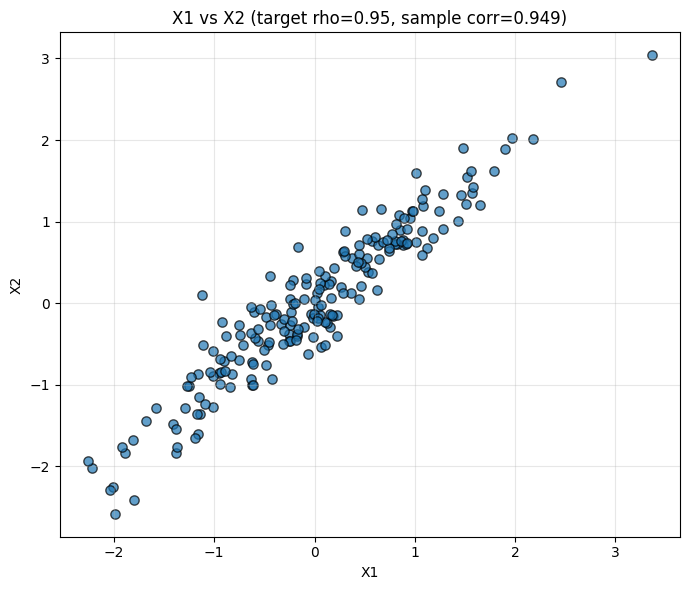


Head of the X1, X2, Y table:
       X1        X2         Y
-0.468604 -0.512327 -4.068619
-0.880353 -0.398729 -3.556269
 0.268228  0.194188  1.124263
-1.680690 -1.438006 -7.628416
 0.377783  0.549355  1.953565

Fitting OLS regression with statsmodels...

Statsmodels coefficients and standard errors:
           coef      bses
const -0.087890  0.070493
X1     1.818398  0.235530
X2     3.114614  0.233449

Regression summary:
                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.957
Model:                            OLS   Adj. R-squared:                  0.957
Method:                 Least Squares   F-statistic:                     2192.
Date:                Thu, 14 May 2026   Prob (F-statistic):          2.53e-135
Time:                        09:44:30   Log-Likelihood:                -281.49
No. Observations:                 200   AIC:                             569.0
Df Residuals:        

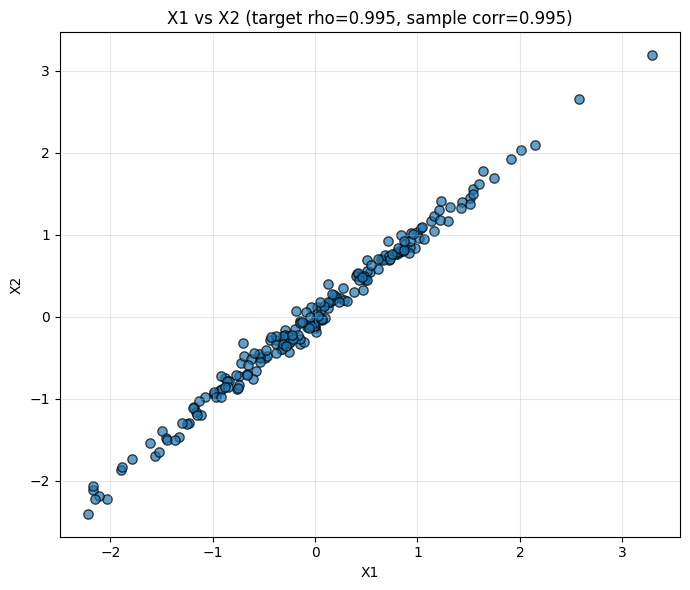


Head of the X1, X2, Y table:
       X1        X2         Y
-0.489180 -0.503006 -4.081805
-0.723030 -0.570727 -3.757616
 0.245567  0.222154  1.162839
-1.615609 -1.538866 -7.800835
 0.441759  0.496015  1.921498

Fitting OLS regression with statsmodels...

Statsmodels coefficients and standard errors:
           coef      bses
const -0.087890  0.070493
X1     1.498527  0.734033
X2     3.435245  0.731952

Regression summary:
                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.958
Model:                            OLS   Adj. R-squared:                  0.957
Method:                 Least Squares   F-statistic:                     2237.
Date:                Thu, 14 May 2026   Prob (F-statistic):          3.67e-136
Time:                        09:44:30   Log-Likelihood:                -281.49
No. Observations:                 200   AIC:                             569.0
Df Residuals:        

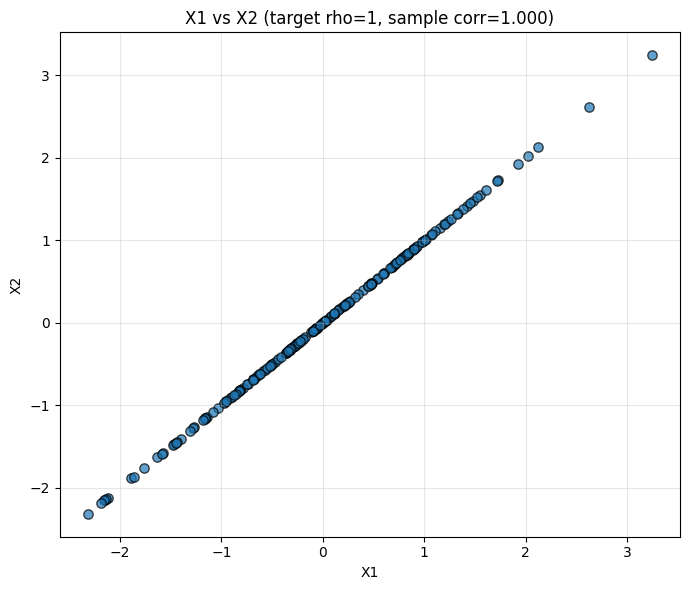


Head of the X1, X2, Y table:
       X1        X2         Y
-0.496714 -0.496714 -4.077998
-0.647689 -0.647689 -3.837818
 0.234153  0.234153  1.176011
-1.579213 -1.579213 -7.849083
 0.469474  0.469474  1.897306

Fitting OLS regression with statsmodels...

Statsmodels coefficients and standard errors:
               coef          bses
const -8.788966e-02  7.049345e-02
X1     5.717902e+06  8.937297e+06
X2    -5.717897e+06  8.937297e+06

Regression summary:
                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.958
Model:                            OLS   Adj. R-squared:                  0.957
Method:                 Least Squares   F-statistic:                     2241.
Date:                Thu, 14 May 2026   Prob (F-statistic):          3.14e-136
Time:                        09:44:30   Log-Likelihood:                -281.49
No. Observations:                 200   AIC:                        

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

def multicollinearity_demo(rho, n=200, alpha=2.0, beta=3.0, noise_sd=1.0, seed=42):
    """
    Generate X1, X2 from a correlated bivariate Gaussian, then create
    Y = alpha*X1 + beta*X2 + noise.

    Displays:
      1) scatter plot of X1 vs X2
      2) head of the table [X1, X2, Y]
      3) statsmodels coefficients and standard errors
      4) VIF for X1 and X2
    """
    print("=" * 80)
    print(f"Multicollinearity demo with target correlation rho = {rho}")
    print("=" * 80)
    print(f"Generating n = {n} observations")
    print(f"Model: Y = {alpha}*X1 + {beta}*X2 + noise, noise_sd = {noise_sd}")
    print()

    np.random.seed(seed)

    # Covariance matrix for bivariate normal with unit variances
    cov = np.array([[1.0, rho],
                    [rho, 1.0]])

    mean = np.array([0.0, 0.0])
    X = np.random.multivariate_normal(mean, cov, size=n)

    X1 = X[:, 0]
    X2 = X[:, 1]
    noise = np.random.normal(0.0, noise_sd, size=n)
    Y = alpha * X1 + beta * X2 + noise

    df = pd.DataFrame({"X1": X1, "X2": X2, "Y": Y})

    # -----------------------------
    # 1) Plot X1 vs X2
    # -----------------------------
    sample_corr = np.corrcoef(X1, X2)[0, 1]
    print(f"Sample correlation corr(X1, X2) = {sample_corr:.4f}")
    print("Plotting X1 vs X2...")

    plt.figure(figsize=(7, 6))
    plt.scatter(X1, X2, alpha=0.7, edgecolor="k", s=45)
    plt.title(f"X1 vs X2 (target rho={rho}, sample corr={sample_corr:.3f})")
    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # -----------------------------
    # 2) Display head of table
    # -----------------------------
    print("\nHead of the X1, X2, Y table:")
    print(df.head().to_string(index=False))

    # -----------------------------
    # 3) Statsmodels regression
    # -----------------------------
    print("\nFitting OLS regression with statsmodels...")
    X_design = sm.add_constant(df[["X1", "X2"]])
    model = sm.OLS(df["Y"], X_design)
    results = model.fit()

    print("\nStatsmodels coefficients and standard errors:")
    coef_table = pd.DataFrame({
        "coef": results.params,
        "bses": results.bse
    })
    print(coef_table.to_string())

    print("\nRegression summary:")
    print(results.summary())

    # -----------------------------
    # 4) VIF
    # -----------------------------
    print("\nComputing Variance Inflation Factors (VIF)...")
    vif_df = pd.DataFrame()
    vif_df["variable"] = ["X1", "X2"]
    vif_df["VIF"] = [
        variance_inflation_factor(df[["X1", "X2"]].values, 0),
        variance_inflation_factor(df[["X1", "X2"]].values, 1)
    ]
    print(vif_df.to_string(index=False))

    print("\nInterpretation:")
    print(" - As X1 and X2 become more correlated, VIF increases.")
    print(" - Larger VIF typically corresponds to larger standard errors (bses).")
    print(" - This is the multicollinearity effect you want to illustrate.")
    print("=" * 80)
    print()

    return df, results, vif_df


# ---------------------------------------------------------
# Call the function for several correlation levels
# ---------------------------------------------------------
correlations = [0.0, 0.5, 0.8, 0.95, 0.995, 1]

for rho in correlations:
    multicollinearity_demo(
        rho=rho,
        n=200,
        alpha=2.0,
        beta=3.0,
        noise_sd=1.0,
        seed=42
    )

2 X1 + 3 X2 = Y
X1 = X2
5 X1 = Y
5 X2 = Y
10 X1 - 5 X2 = Y
5000005 X1 - 5000000 X2 = Y
2.5 X1 + 2.5 X2 = Y
    
#2 X1 + 3 X2 = Y
#X1 = X2
#5 X1 = Y
#A X1 + B X2 = Y
#A + B = 5

## Misconception 4: “Multicollinearity means predictions must be bad”

# Variance Inflation Factor

## Why Variance Inflation Factor matters

## Variance Inflation Factor is a way of assessing the degree of multicollinearity

SINGLE MULTICOLLINEARITY EXAMPLE: corr(X1, X2) = 0.95

Generating n = 200 observations from a bivariate Gaussian with correlation rho = 0.95
Model for Y: Y = 2.0*X1 + 3.0*X2 + noise, noise_sd = 1.0
Sample correlation corr(X1, X2) = 0.9493

Plotting X1 vs X2 to show the strong correlation...


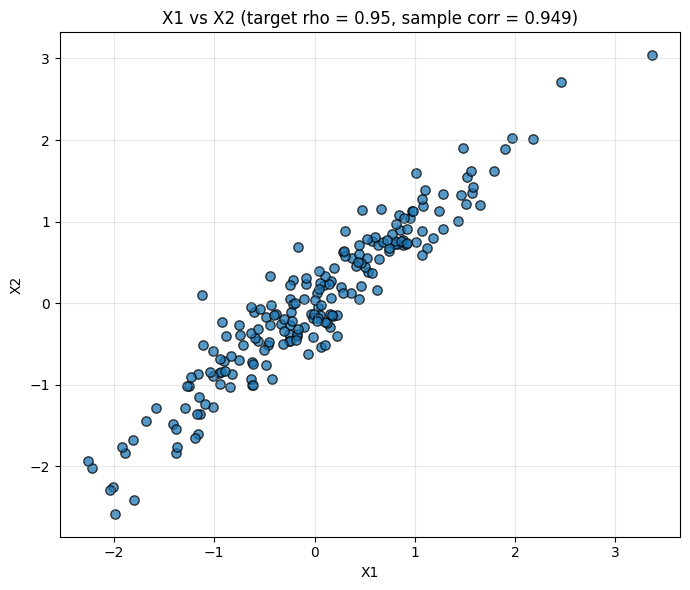


Head of the X1, X2, Y table:
       X1        X2         Y
-0.468604 -0.512327 -4.068619
-0.880353 -0.398729 -3.556269
 0.268228  0.194188  1.124263
-1.680690 -1.438006 -7.628416
 0.377783  0.549355  1.953565

Fitting OLS regression: Y ~ X1 + X2

Statsmodels coefficients and standard errors:
           coef      bses
const -0.087890  0.070493
X1     1.818398  0.235530
X2     3.114614  0.233449

Computing Variance Inflation Factors (VIF)...
variable       VIF
      X1 10.104883
      X2 10.104883

EXPLANATION OF VIF

The Variance Inflation Factor for a predictor X_j is defined by:

    VIF_j = 1 / (1 - R_j^2)

where R_j^2 is the R^2 value from regressing X_j on all of the other predictors.

In this example, with only two predictors:

    VIF(X1) = 1 / (1 - R_1^2)

where R_1^2 comes from the auxiliary regression:

    X1 = a0 + a1 * X2 + error

and similarly,

    VIF(X2) = 1 / (1 - R_2^2)

where R_2^2 comes from:

    X2 = b0 + b1 * X1 + error

Interpretation:
- If X1 and X2 are nearly

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor

print("=" * 80)
print("SINGLE MULTICOLLINEARITY EXAMPLE: corr(X1, X2) = 0.95")
print("=" * 80)

# -----------------------------
# 1) Generate correlated X1, X2
# -----------------------------
rho = 0.95
n = 200
alpha = 2.0
beta = 3.0
noise_sd = 1.0
seed = 42

print(f"\nGenerating n = {n} observations from a bivariate Gaussian with correlation rho = {rho}")
print(f"Model for Y: Y = {alpha}*X1 + {beta}*X2 + noise, noise_sd = {noise_sd}")

np.random.seed(seed)

cov = np.array([
    [1.0, rho],
    [rho, 1.0]
])

mean = np.array([0.0, 0.0])
X = np.random.multivariate_normal(mean, cov, size=n)

X1 = X[:, 0]
X2 = X[:, 1]
noise = np.random.normal(0.0, noise_sd, size=n)
Y = alpha * X1 + beta * X2 + noise

df = pd.DataFrame({"X1": X1, "X2": X2, "Y": Y})

sample_corr = np.corrcoef(X1, X2)[0, 1]
print(f"Sample correlation corr(X1, X2) = {sample_corr:.4f}")

# -----------------------------
# 2) Plot X1 vs X2
# -----------------------------
print("\nPlotting X1 vs X2 to show the strong correlation...")
plt.figure(figsize=(7, 6))
plt.scatter(X1, X2, alpha=0.75, s=45, edgecolor="k")
plt.title(f"X1 vs X2 (target rho = {rho}, sample corr = {sample_corr:.3f})")
plt.xlabel("X1")
plt.ylabel("X2")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# -----------------------------
# 3) Show table head
# -----------------------------
print("\nHead of the X1, X2, Y table:")
print(df.head().to_string(index=False))

# -----------------------------
# 4) Fit regression and show coefficients/bses
# -----------------------------
print("\nFitting OLS regression: Y ~ X1 + X2")
X_design = sm.add_constant(df[["X1", "X2"]])
results = sm.OLS(df["Y"], X_design).fit()

coef_table = pd.DataFrame({
    "coef": results.params,
    "bses": results.bse
})

print("\nStatsmodels coefficients and standard errors:")
print(coef_table.to_string())

# -----------------------------
# 5) Compute VIF
# -----------------------------
print("\nComputing Variance Inflation Factors (VIF)...")
vif_df = pd.DataFrame({
    "variable": ["X1", "X2"],
    "VIF": [
        variance_inflation_factor(df[["X1", "X2"]].values, 0),
        variance_inflation_factor(df[["X1", "X2"]].values, 1)
    ]
})
print(vif_df.to_string(index=False))

# -----------------------------
# 6) Print explanation of VIF with equations
# -----------------------------
print("\n" + "=" * 80)
print("EXPLANATION OF VIF")
print("=" * 80)

print("""
The Variance Inflation Factor for a predictor X_j is defined by:

    VIF_j = 1 / (1 - R_j^2)

where R_j^2 is the R^2 value from regressing X_j on all of the other predictors.

In this example, with only two predictors:

    VIF(X1) = 1 / (1 - R_1^2)

where R_1^2 comes from the auxiliary regression:

    X1 = a0 + a1 * X2 + error

and similarly,

    VIF(X2) = 1 / (1 - R_2^2)

where R_2^2 comes from:

    X2 = b0 + b1 * X1 + error

Interpretation:
- If X1 and X2 are nearly uncorrelated, then R^2 is small and VIF is near 1.
- If X1 and X2 are highly correlated, then R^2 is close to 1 and VIF becomes large.
- Large VIF means the coefficient standard errors in the main regression tend to be inflated.

A useful intuition is:

    Var(\\hat{\\beta}_j) is multiplied by VIF_j

relative to the case where the predictors are uncorrelated.

So high correlation between X1 and X2 makes it harder to separate their individual effects,
which is why the standard errors (bses) become larger.
""")

# -----------------------------
# 7) Optional compact interpretation
# -----------------------------
print("Summary:")
print(f"  corr(X1, X2) = {sample_corr:.4f}")
print(f"  VIF(X1) = {vif_df.loc[vif_df['variable'] == 'X1', 'VIF'].iloc[0]:.4f}")
print(f"  VIF(X2) = {vif_df.loc[vif_df['variable'] == 'X2', 'VIF'].iloc[0]:.4f}")
print("  High VIF indicates strong multicollinearity and inflated standard errors.")

# Interaction Term

## Why interaction terms matter

## When interaction happens in a real dataset, it's important to be able to include the term; otherwise, the model will be a poor fit.

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

print("=" * 80)
print("REAL-LIFE INTERACTION EXAMPLE: Y ~ X1 + X2 + X1*X2")
print("=" * 80)

print("""
Real-life scenario:
Suppose we are modeling sales.

- X1 = advertising spend
- X2 = website traffic
- Y  = sales

Why include an interaction term X1 * X2?

The effect of advertising may depend on how much website traffic is already present.
For example:
- If traffic is low, extra advertising may not convert very well.
- If traffic is high, extra advertising may have a much larger effect.

That means the impact of X1 is not constant across all values of X2.
An interaction term X1 * X2 allows the effect of X1 to change with X2.

Model:
    Y = b0 + b1*X1 + b2*X2 + b3*(X1*X2) + error

If b3 is meaningfully different from 0, the interaction matters.
""")

# -----------------------------
# Generate example data
# -----------------------------
np.random.seed(7)
n = 200

print("Generating synthetic data...")
X1 = np.random.uniform(0, 100, n)      # advertising spend
X2 = np.random.uniform(0, 1000, n)     # website traffic

# True coefficients
b0_true = 20
b1_true = 0.8
b2_true = 0.03
b3_true = 0.002

noise = np.random.normal(0, 15, n)

Y = b0_true + b1_true * X1 + b2_true * X2 + b3_true * (X1 * X2) + noise

df = pd.DataFrame({
    "X1": X1,
    "X2": X2,
    "X1_X2": X1 * X2,
    "Y": Y
})

print("\nHead of the data:")
print(df.head().to_string(index=False))

# -----------------------------
# Fit regression with interaction
# -----------------------------
print("\nFitting OLS model with X1, X2, and X1*X2...")

X_design = df[["X1", "X2"]].copy()
X_design["X1_X2"] = df["X1"] * df["X2"]
X_design = sm.add_constant(X_design)

results = sm.OLS(df["Y"], X_design).fit()

print("\nFitted coefficients and standard errors:")
coef_table = pd.DataFrame({
    "coef": results.params,
    "bses": results.bse
})
print(coef_table.to_string())

print("\nFull statsmodels summary:")
print(results.summary())

print("\nInterpretation:")
print("- The coefficient on X1 is the effect of advertising spend when website traffic = 0.")
print("- The coefficient on X2 is the effect of website traffic when advertising spend = 0.")
print("- The interaction coefficient on X1_X2 tells us how the effect of advertising changes as traffic changes.")
print("- If the interaction coefficient is statistically significant, the variables interact non-additively.")

print("\nTrue coefficients used to generate the data:")
print(f"  intercept = {b0_true}")
print(f"  X1        = {b1_true}")
print(f"  X2        = {b2_true}")
print(f"  X1*X2     = {b3_true}")

REAL-LIFE INTERACTION EXAMPLE: Y ~ X1 + X2 + X1*X2

Real-life scenario:
Suppose we are modeling sales.

- X1 = advertising spend
- X2 = website traffic
- Y  = sales

Why include an interaction term X1 * X2?

The effect of advertising may depend on how much website traffic is already present.
For example:
- If traffic is low, extra advertising may not convert very well.
- If traffic is high, extra advertising may have a much larger effect.

That means the impact of X1 is not constant across all values of X2.
An interaction term X1 * X2 allows the effect of X1 to change with X2.

Model:
    Y = b0 + b1*X1 + b2*X2 + b3*(X1*X2) + error

If b3 is meaningfully different from 0, the interaction matters.

Generating synthetic data...

Head of the data:
       X1         X2        X1_X2          Y
 7.630829 751.953561  5738.028994  59.082501
77.991879  61.665330  4809.394983 114.756163
43.840923 744.823674 32653.757434 123.979260
72.346518 946.275927 68459.768193 220.721204
97.798951 603.559552

## Misconception 5: “An interaction term means two variables are correlated”

## Correlation is about whether X1 and X2 move together. Interaction is about whether the effect of X1 on Y changes depending on X2.